# AquaTrace: build the website ML model (Google Colab)

**Input:** `AquaTrace_Master_Data.xlsx` (sheet `paired_samples`): 28,046 real US river samples where the lab tested medicines **and** sensors were read at the same site on the same day.

**Output (files for Phi's website, folder `frontend/models/`):**
| File | What the website does with it |
|---|---|
| `aquatrace_colab_model.json` (+ `.js` copy) | **Estimation model → Load Colab model / Model file…** runs these trees in the browser |
| `crosscheck_lab_results.csv` (+ `.js` copy) | **Lab results → Held-out US lab results** = real lab results from rivers the model never saw → the website cross-checks them |

The `.js` copies hold the same data. They let the website work when `index.html` is simply double-clicked (browsers block reading `.json`/`.csv` from a file without a server).

**Two models per medicine (每种药两个模型):**
1. **Screening model (筛查模型):** "Is this water likely HIGH for this medicine?" → probability. This is the strong one.
2. **Level model (浓度模型):** "If present, roughly how much?" → µg/L. Weaker, so shown with a wide range.

**Honest test (诚实测试):** 20% of river **sites** are held back completely. The model never sees them. The website re-checks the model on exactly these samples.

In [1]:
import json, datetime as dt, numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings; warnings.filterwarnings('ignore')
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_predict
from sklearn.metrics import r2_score, roc_auc_score
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr, pearsonr

# On Colab: upload the master workbook first
# from google.colab import files; files.upload()
raw = pd.read_excel('AquaTrace_Master_Data.xlsx', sheet_name='paired_samples')
df = raw.rename(columns={'conductivity_uScm':'conductivity','turbidity_NTU':'turbidity','temp_C':'temp','do_mgL':'do'})
df['date'] = df['date'].astype(str).str[:10]
print(df.shape, '| sites:', df.site.nunique())

(28046, 27) | sites: 5983


## Step 1: Clean (清洗)
Remove impossible readings (typing or unit errors), using the same ranges as the analysis notebook.

In [2]:
rng = {'ph':(3,11), 'do':(0,20), 'conductivity':(1,60000), 'temp':(-1,40), 'turbidity':(0,4000)}
for c,(lo,hi) in rng.items():
    df.loc[(df[c]<lo)|(df[c]>hi), c] = np.nan
df[list(rng)].describe().round(2)

,ph,do,conductivity,temp,turbidity
count,23700.00,13991.00,20166.00,23179.00,14015.00
mean,7.35,7.04,2132.50,19.06,32.17
std,0.84,2.77,7770.83,7.29,128.66
min,3.00,0.01,2.42,-0.80,0.00
25%,7.00,5.20,140.00,14.60,2.70
50%,7.49,7.10,337.50,20.40,5.80
75%,7.91,8.73,689.50,24.50,16.00
max,10.20,19.77,59101.00,39.90,3240.00


## Step 2: Choose sensors per medicine (选传感器)
The website can only estimate when **every** input sensor has a value. Asking for all 5 sensors throws away most samples, so each medicine uses the combination with the best **coverage × accuracy** (see sheet `analysis_sensor_subsets`).

| Medicine | Sensors | Why |
|---|---|---|
| Carbamazepine, atenolol, sulfamethoxazole | pH + temperature + conductivity | conductivity tracks treated sewage |
| Paracetamol | pH + turbidity + temperature + **DO** | fresh sewage uses up oxygen |
| Caffeine | pH + turbidity + conductivity | raw-sewage marker |

In [3]:
COMPS = [  # website id, medicine in data, display name, sensors
    ('CBZ-US', 'Carbamazepine',    'Carbamazepine (US model)',    ['ph','temp','conductivity']),
    ('PCM-US', 'Acetaminophen',    'Paracetamol (US model)',      ['ph','turbidity','temp','do']),
    ('ATL-US', 'Atenolol',         'Atenolol (US model)',         ['ph','temp','conductivity']),
    ('SMX-US', 'Sulfamethoxazole', 'Sulfamethoxazole (US model)', ['ph','temp','conductivity']),
    ('CAF-US', 'Caffeine',         'Caffeine (US model)',         ['ph','turbidity','conductivity']),
]
INFO = {'Carbamazepine':('Anticonvulsant','298-46-4',2.45), 'Acetaminophen':('Analgesic / antipyretic','103-90-2',0.46),
        'Atenolol':('Beta-blocker','29122-68-7',0.16), 'Sulfamethoxazole':('Antibiotic (sulfonamide)','723-46-6',0.89),
        'Caffeine':('Stimulant, raw-sewage marker','58-08-2',-0.07)}
ALLF = ['ph','turbidity','temp','conductivity','do']
UNIT, FAC = 'µg/L', 1e-3   # website shows µg/L (ng/L × 0.001)
CLF = dict(n_estimators=60, max_depth=8, min_samples_leaf=10, max_features=0.6, class_weight='balanced', random_state=0, n_jobs=-1)
REG = dict(n_estimators=60, max_depth=8, min_samples_leaf=8, max_features=0.6, random_state=0, n_jobs=-1)

## Step 3: Define "high" and split sites (定义"高" + 分开测试点)
- **High** = above the median of all US detections for that medicine (e.g. carbamazepine 11.9 ng/L). A **screening level**, not a safety limit.
- Not detected → counts as "low" only if the lab could see down to that level; otherwise unknown and dropped.
- Not detected → stored as **detection limit ÷ 2** (same rule as the website).
- **20% of sites held back** (GroupShuffleSplit, seed 42).

In [4]:
def export_tree(est, clf):
    # website tree format: [feature, threshold, left, right] for a split, [value] for a leaf (x <= threshold goes left)
    t = est.tree_; nodes = []
    for i in range(t.node_count):
        if t.children_left[i] == -1:
            v = t.value[i][0]; nodes.append([round(float(v[1]/v.sum()) if clf else float(v[0]), 6)])
        else:
            nodes.append([int(t.feature[i]), round(float(t.threshold[i]),5), int(t.children_left[i]), int(t.children_right[i])])
    return nodes

def screen_metrics(p, h, thr):
    f = p >= thr; h = h.astype(bool)
    return {'auc': roc_auc_score(h, p), 'flagged_share': f.mean(), 'hit_rate': h[f].mean() if f.any() else np.nan,
            'base_rate': h.mean(), 'caught_share': f[h].mean() if h.any() else np.nan, 'agree': (f == h).mean()}

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
pkg = {'format':'aquatrace-model-package/2', 'created': dt.datetime.now(dt.timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ'),
       'source':'US Water Quality Portal (USGS/EPA), river sites 1999-2025: lab results paired with same-site, same-day field readings',
       'note':"Screening model = probability the medicine is above the 'high' level (median of US detections). Level model = expected concentration when present. 20% of sites held back for cross-checking.",
       'models':{}, 'compounds':[]}
report, cross_rows, imps = [], [], {}

## Step 4: Train and test (训练 + 测试) ⭐
For each medicine:
1. **Screening model** = random forest classifier, 5-fold cross-validation **grouped by site**
2. **Flag rule** = flag a reading if its score is in the **riskiest 10%** of training readings
3. **Level model** = random forest on log10(concentration), detected samples only
4. Score both on the **held-out sites**

In [5]:
for cid, name, disp, feats in COMPS:
    v, lim = f'{name}_ngL', f'{name}_lim_ngL'
    T = float(np.nanmedian(df[v]))
    d = df[df[feats].notna().all(axis=1) & (df[v].notna() | df[lim].notna())].copy()
    d = d[d[v].notna() | (d[lim] <= T)].copy()
    d['below'] = d[v].isna(); d['conc_ng'] = np.where(d.below, d[lim]/2, d[v]); d['high'] = (d[v] >= T).fillna(False).astype(int)
    tr_i, te_i = next(gss.split(d, groups=d.site)); tr, te = d.iloc[tr_i], d.iloc[te_i]
    # screening model
    clf = RandomForestClassifier(**CLF)
    oofp = cross_val_predict(clf, tr[feats].values, tr.high.values, cv=GroupKFold(5), groups=tr.site.values, method='predict_proba')[:,1]
    pthr = float(np.quantile(oofp, 0.90))
    clf.fit(tr[feats].values, tr.high.values); pte = clf.predict_proba(te[feats].values)[:,1]
    s_cv, s_te = screen_metrics(oofp, tr.high.values, pthr), screen_metrics(pte, te.high.values, pthr)
    # level model
    trd, ted = tr[~tr.below], te[~te.below]; yl, yt = np.log10(trd.conc_ng.values), np.log10(ted.conc_ng.values)
    reg = RandomForestRegressor(**REG)
    oofl = cross_val_predict(reg, trd[feats].values, yl, cv=GroupKFold(5), groups=trd.site.values)
    reg.fit(trd[feats].values, yl); tel = reg.predict(ted[feats].values)
    lvl = {'r2_log_cv': r2_score(yl, oofl), 'within2x_cv': np.mean(np.abs(oofl-yl) <= np.log10(2)), 'rmse_log_cv': float(np.sqrt(np.mean((oofl-yl)**2))),
           'r2_log_holdout': r2_score(yt, tel), 'within2x_holdout': np.mean(np.abs(tel-yt) <= np.log10(2))}
    pi = permutation_importance(clf, te[feats].values, te.high.values, n_repeats=8, random_state=0, scoring='roc_auc')
    imp = np.clip(pi.importances_mean, 0, None); imp = imp/(imp.sum() or 1); imps[disp] = dict(zip(feats, imp))
    conc_trd = trd.conc_ng.values*FAC; oof_conc = 10**oofl*FAC
    sub = np.random.default_rng(0).choice(len(trd), size=min(400, len(trd)), replace=False)
    pkg['models'][cid] = {'name':disp, 'unit':UNIT, 'ng_to_unit':FAC, 'feats':feats, 'threshold':T*FAC, 'threshold_ngL':round(T,2), 'p_threshold':pthr,
        'n':int(len(tr)), 'n_detected':int(len(trd)), 'n_sites':int(tr.site.nunique()), 'n_holdout':int(len(te)), 'n_holdout_sites':int(te.site.nunique()),
        'screen_cv':{k:round(float(x),3) for k,x in s_cv.items()}, 'screen_holdout':{k:round(float(x),3) for k,x in s_te.items()},
        'level':{k:round(float(x),3) for k,x in lvl.items()}, 'ranges':[[float(tr[f].min()), float(tr[f].max())] for f in feats],
        'importance':sorted([{'f':f,'v':round(float(x),4)} for f,x in zip(feats, imp)], key=lambda r:-r['v']),
        'corr':[{'f':f,'r':round(float(pearsonr(trd[f], yl)[0]),3),'rho':round(float(spearmanr(trd[f], trd.conc_ng)[0]),3)} for f in feats],
        'oof':[{'y':float(conc_trd[i]),'yhat':float(oof_conc[i]),'id':f'{trd.site.iloc[i]} {trd.date.iloc[i]}','below':False} for i in sub],
        'clf_trees':[export_tree(e, True) for e in clf.estimators_], 'reg_trees':[export_tree(e, False) for e in reg.estimators_]}
    cls_, cas, kow = INFO[name]
    pkg['compounds'].append({'id':cid, 'name':disp, 'cls':cls_, 'cas':cas, 'kow':kow, 'unit':UNIT, 'level':round(T*FAC,5), 'pnec':None, 'bg':0, 'rt':None,
        'method':'US labs (mostly LC-MS/MS), Water Quality Portal', 'src':f'US-trained model package. Level = median of US detections ({T:.1f} ng/L); screening only, not a safety limit.'})
    report.append({'medicine':disp, 'sensors':' + '.join(feats), 'high above (ng/L)':round(T,1), 'train samples':len(tr), 'held-out samples':len(te), 'held-out sites':te.site.nunique(),
                   'AUC (held-out)':round(s_te['auc'],3), 'flagged → really high':f"{s_te['hit_rate']:.0%}", 'random':f"{s_te['base_rate']:.0%}",
                   'lift':round(s_te['hit_rate']/s_te['base_rate'],1), 'high caught':f"{s_te['caught_share']:.0%}", 'level R² (log, held-out)':round(lvl['r2_log_holdout'],2),
                   'level within 2× (held-out)':f"{lvl['within2x_holdout']:.0%}"})
    for i,(_,r) in enumerate(te.sort_values('date').iterrows()):
        row = {'sample_id':f'{cid}-{i+1:03d}', 'timestamp':f'{r.date}T12:00:00Z', 'lat':r.lat, 'lon':r.lon, 'compound':cid,
               'concentration':'<LOD' if r.below else f'{r.conc_ng*FAC:.6g}', 'unit':UNIT, 'lod':f'{r[lim]*FAC:.6g}' if r.below else '',
               'method':'US lab, Water Quality Portal', 'notes':f'held-out site {r.site}'}
        for f in ALLF: row[f] = '' if pd.isna(r[f]) else round(float(r[f]),4)
        cross_rows.append(row)
R = pd.DataFrame(report).set_index('medicine'); R

,sensors,high above (ng/L),train samples,held-out samples,held-out sites,AUC (held-out),flagged → really high,random,lift,high caught,"level R² (log, held-out)",level within 2× (held-out)
medicine,,,,,,,,,,,,
Carbamazepine (US model),ph + temp + conductivity,11.9,8947,2286,577,0.749,23%,6%,3.6,40%,0.12,40%
Paracetamol (US model),ph + turbidity + temp + do,42.0,6228,1647,387,0.713,9%,3%,3.1,28%,0.10,44%
Atenolol (US model),ph + temp + conductivity,30.8,1059,253,111,0.873,31%,7%,4.4,78%,0.26,54%
Sulfamethoxazole (US model),ph + temp + conductivity,38.4,1451,382,140,0.860,71%,22%,3.2,44%,0.52,63%
Caffeine (US model),ph + turbidity + conductivity,100.0,3140,680,241,0.709,59%,23%,2.6,19%,-0.01,44%


**How to read it (怎么看):**
- **AUC (held-out):** 0.5 = coin flip, 1.0 = perfect. Atenolol and sulfamethoxazole ≈ 0.86–0.87; carbamazepine 0.75; paracetamol and caffeine ≈ 0.71.
- **Flagged → really high vs random:** e.g. sulfamethoxazole: 71% of flagged readings were truly high, against 22% by random sampling (**3.2× lift**). That is the **lab-cost saving (节省化验成本)**.
- **Level model** is weak (R² 0.1–0.5). The website shows it with a wide range and leads with screening.

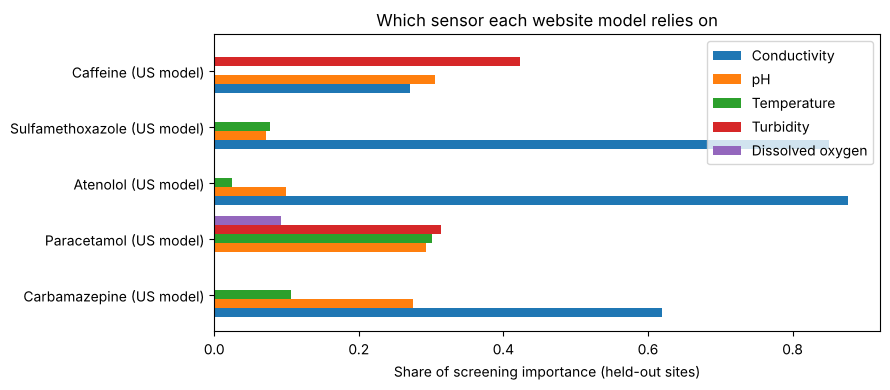

In [6]:
I = pd.DataFrame(imps).T.fillna(0)[['conductivity','ph','temp','turbidity','do']]
I.columns = ['Conductivity','pH','Temperature','Turbidity','Dissolved oxygen']
ax = I.plot.barh(figsize=(9,4), width=0.8); ax.set_xlabel('Share of screening importance (held-out sites)')
ax.set_title('Which sensor each website model relies on'); plt.tight_layout(); plt.show()

## Step 5: Export for the website (导出给网站)

In [7]:
pkg['not_modelled'] = {'DIC':'Diclofenac: only 62 detections in US river data (10 above 22.8 ng/L); needs Penang samples',
                       'KTP':'Ketoprofen: only 3 detections in US river data'}
json.dump(pkg, open('aquatrace_colab_model.json','w'), separators=(',',':'))
pd.DataFrame(cross_rows).to_csv('crosscheck_lab_results.csv', index=False)
# same data wrapped as .js, so the website also works when index.html is opened by double-click (no server)
open('aquatrace_colab_model.js','w').write('window.AQUATRACE_MODEL=' + json.dumps(pkg, separators=(',',':')) + ';\n')
open('crosscheck_lab_results.js','w', encoding='utf-8').write('window.AQUATRACE_CROSSCHECK_CSV=' + json.dumps(open('crosscheck_lab_results.csv', encoding='utf-8').read()) + ';\n')
import os
print('aquatrace_colab_model.json', round(os.path.getsize('aquatrace_colab_model.json')/1e6,2), 'MB |', len(pkg['models']), 'models')
print('crosscheck_lab_results.csv', len(cross_rows), 'held-out lab results')
# On Colab: download both files
# from google.colab import files\n# for f in ['aquatrace_colab_model.json','aquatrace_colab_model.js','crosscheck_lab_results.csv','crosscheck_lab_results.js']: files.download(f)

aquatrace_colab_model.json 0.72 MB | 5 models
crosscheck_lab_results.csv 5248 held-out lab results


## Step 6: Put it on the website (放到网站)
1. Copy the 4 files into `frontend/models/` in the website folder (replace the old ones).
2. Double-click `frontend/index.html` → **Estimation model** → **Load Colab model** (or **Model file…** to pick a JSON you just downloaded from Colab).
3. **Lab results** → **Held-out US lab results**: imports the held-out samples and runs the **cross-check**.
4. The **Cross-check: model vs lab** table should show the same AUC as Step 4 (the "AUC Colab" column). If it matches, the website runs exactly the model built here.

**Live Penang boat readings** also get an estimate. Coastal seawater conductivity is far outside the US training range, so the website marks those estimates **Low confidence**. This is correct: the model must be recalibrated with Penang samples before it can be trusted there.